In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()

## radar-chart

**Figure 1: Accuracy (%) of three 8–9B models on six benchmarks.** Labels give Ours-8B's score at each benchmark. Ours-8B has the most balanced profile, staying within 2.9 points of the best model everywhere, with its largest gains on MATH (41.5, +4.9 over Gemma-2-9B) and GSM8K (79.6, +4.5 over Llama-3-8B).

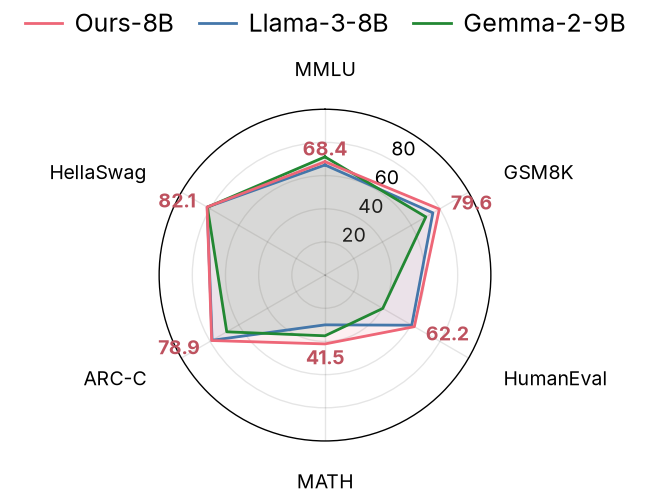

In [2]:
with open("../radar-chart.json") as f:
    data = json.load(f)
names = data["benchmarks"]
scores = data["scores"]
angles = np.linspace(0, 2 * np.pi, len(names), endpoint=False)

fig, ax = plt.subplots(figsize=(3.25, 3.25), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

handles = {}
for model, color in [("Llama-3-8B", colors["series-1"]), ("Gemma-2-9B", colors["series-3"]), ("Ours-8B", colors["ours"])]:
    values = np.array(scores[model])
    (handles[model],) = ax.plot(np.r_[angles, angles[:1]], np.r_[values, values[:1]], color=color, label=model)
    ax.fill(angles, values, color=color, alpha=0.1)

sides = ["center" if abs(np.sin(a)) < 0.1 else "left" if np.sin(a) > 0 else "right" for a in angles]
for angle, value, side in zip(angles, scores["Ours-8B"], sides):
    ax.text(angle, value + 8, f"{value:.1f}", fontsize=7, fontweight="bold", color=darken(colors["ours"]), ha=side, va="center")

ax.set_ylim(0, 100)
ax.set_yticks([20, 40, 60, 80])
ax.set_rlabel_position(30)
ax.set_xticks(angles, labels=names)
ax.tick_params(axis="x", pad=6)
for label, side in zip(ax.get_xticklabels(), sides):
    label.set_horizontalalignment(side)

order = ["Ours-8B", "Llama-3-8B", "Gemma-2-9B"]
fig.legend([handles[m] for m in order], order, loc="outside upper center", ncol=3, frameon=False, borderaxespad=0)

fit_height(fig, ax)
fig.savefig("radar-chart.pdf")
fig.savefig("radar-chart.png")
plt.show()